In [1]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kruskal
from statsmodels.stats.multitest import multipletests
from astropy.timeseries import LombScargle
from matplotlib.lines import Line2D
import math
from matplotlib.ticker import ScalarFormatter
import scikit_posthocs as sp
from itertools import combinations


<h3 style="color: #e19edc;"> Lectura parámetros estimados de todos los espectros</h3>

In [2]:
ruta = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Parámetros para análisis de Antares\Resultados perfiles halpha útiles 2018-2026.xlsx"
datos = pd.read_excel(ruta)
datos

,Época,Componente,Centro [Å],z,Velocidad obs. [km/s],Velocidad heliocéntrica [km/s],Profundidad / Altura,FWHM [Å],EW [Å],Archivo
0,Julio 24-2018,Emisión Azul Hα,6561.874,-0.000140,-42.83,-65.66,0.10,0.68,0.08,2018-2019
1,Julio 24-2018,Absorción Hα,6562.893,0.000012,3.68,-19.15,0.80,1.08,0.92,2018-2019
2,Julio 24-2018,Absorción Cobalto,6563.829,0.000066,19.71,-3.12,0.56,0.94,0.62,2018-2019
3,Julio 27-2018,Emisión Azul Hα,6561.847,-0.000150,-44.10,-67.97,0.14,0.95,0.17,2018-2019
4,Julio 27-2018,Absorción Hα,6562.896,0.000013,3.82,-20.05,0.79,1.07,0.91,2018-2019
...,...,...,...,...,...,...,...,...,...,...
130,Septiembre 29-2026,Absorción Hα,6562.719,-0.000014,-4.23,-30.81,0.79,1.61,1.39,2024-2026
131,Septiembre 29-2026,Absorción Cobalto,6563.856,0.000070,20.95,-5.63,0.55,1.14,0.77,2024-2026
132,Octubre 16-2026,Emisión Azul Hα,6561.934,-0.000130,-40.10,-61.71,0.65,1.05,0.86,2024-2026
133,Octubre 16-2026,Absorción Hα,6562.575,-0.000036,-10.83,-32.44,0.82,1.61,1.44,2024-2026


<h4 style="color: #e19edc;"> Análisis estadístico de Spearman</h4>

In [3]:
meses = {'Julio':7,'Agosto':8,'Septiembre':9,'Octubre':10,'Noviembre':11,'Diciembre':12}

def parsear_fecha(s):

    mes, resto = s.strip().split(' ')
    dia, anio = resto.split('-')
    return pd.Timestamp(year=int(anio), month=meses[mes.capitalize()], day=int(dia))

datos = datos.copy()
datos['Fecha'] = datos['Época'].apply(parsear_fecha)
datos['Año'] = datos['Fecha'].dt.year
datos['t'] = datos['Fecha'].dt.year + (datos['Fecha'].dt.dayofyear - 1) / 365.25

datos = datos.rename(columns={
    'Velocidad heliocéntrica [km/s]': 'V_helio',
    'Profundidad / Altura': 'Amp',
    'FWHM [Å]': 'FWHM',
    'EW [Å]': 'EW',})

# Nombres cortos de componentes

datos['Comp'] = datos['Componente'].replace({'Absorción Hα': 'Abs Hα', 'Emisión Azul Hα': 'Emi Hα', 'Absorción Cobalto': 'Co I'})
print(datos['Comp'].unique())

variables = ['V_helio', 'Amp', 'FWHM', 'EW']

['Emi Hα' 'Abs Hα' 'Co I']


<h5 style="color: #e19edc;"> Correlación entre diferentes parámetros</h5>

               var1            var2       rho             p         p_FDR
52          EW_Co I       FWHM_Co I  0.965175  1.138328e-26  1.195244e-24
29       Amp_Emi Hα       EW_Emi Hα  0.961036  1.221387e-25  6.412281e-24
38       Amp_Emi Hα  ΔV_EmiHα_AbsHα  0.940622  8.544006e-22  2.990402e-20
68        EW_Emi Hα  ΔV_EmiHα_AbsHα  0.935430  4.916970e-21  1.290705e-19
100  V_helio_Emi Hα   ΔV_EmiHα_Co I  0.914493  1.666667e-18  3.500000e-17
..              ...             ...       ...           ...           ...
42        EW_Abs Hα       FWHM_Co I  0.362465  1.440843e-02  2.564213e-02
66        EW_Emi Hα   ΔV_AbsHα_Co I -0.358417  1.562326e-02  2.734071e-02
54          EW_Co I  V_helio_Abs Hα -0.350987  1.807930e-02  3.112011e-02
7        Amp_Abs Hα     FWHM_Emi Hα -0.347231  1.944018e-02  3.292289e-02
72      FWHM_Abs Hα    V_helio_Co I -0.330033  2.682349e-02  4.470582e-02

[63 rows x 5 columns]


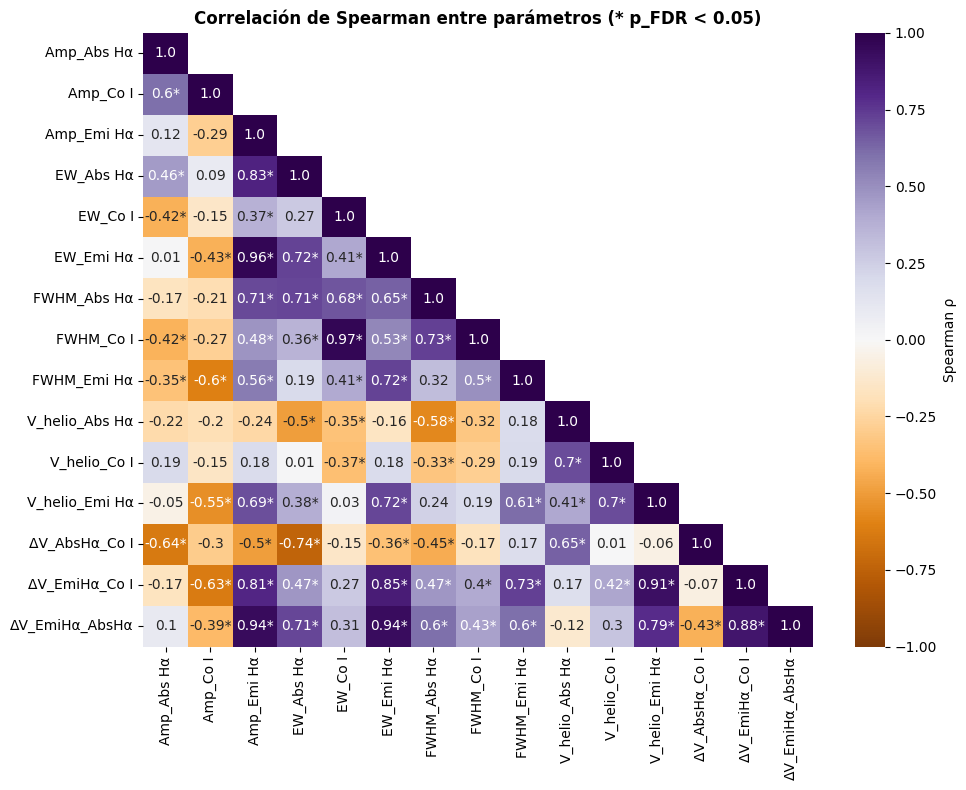

In [4]:
# Una fila por época
ancho = datos.pivot_table(index=['Fecha', 'Año', 't'], columns='Comp', values=variables)
ancho.columns = [f'{v}_{c}' for v, c in ancho.columns]
ancho = ancho.reset_index().sort_values('t')

V_abs, V_emi, V_co = 'V_helio_Abs Hα', 'V_helio_Emi Hα', 'V_helio_Co I'

difs = {'ΔV_AbsHα_Co I':  (V_abs, V_co),
        'ΔV_EmiHα_Co I':  (V_emi, V_co),
        'ΔV_EmiHα_AbsHα': (V_emi, V_abs)}

for nombre, (a, b) in difs.items():
    ancho[nombre] = ancho[a] - ancho[b]


cols = [c for c in ancho.columns if c not in ['Fecha', 'Año', 't']]

def spearman_matriz(d, cols):
    rho = pd.DataFrame(index=cols, columns=cols, dtype=float)
    pv = rho.copy()
    for a in cols:
        for b in cols:
            if a == b:
                rho.loc[a, b] = 1.0
                continue
            sub = d[[a, b]].dropna()
            if len(sub) >= 5:
                r, p = spearmanr(sub[a], sub[b])
                rho.loc[a, b], pv.loc[a, b] = r, p
    return rho, pv

rho, pv = spearman_matriz(ancho, cols)

# Corrección por comparaciones múltiples (FDR)

iu = np.triu_indices(len(cols), k=1)
pvals = pv.values[iu]
ok = ~np.isnan(pvals)
p_fdr = np.full_like(pvals, np.nan)
p_fdr[ok] = multipletests(pvals[ok], method='fdr_bh')[1]

tabla = pd.DataFrame({'var1': np.array(cols)[iu[0]], 'var2': np.array(cols)[iu[1]],
                      'rho': rho.values[iu], 'p': pvals, 'p_FDR': p_fdr})
tabla = tabla.dropna().sort_values('p')
print(tabla[tabla['p_FDR'] < 0.05])   # Riesgo de falsos positivos < 5%

mask = np.triu(np.ones_like(rho, dtype=bool), k=1) 

# Matriz de etiquetas
anotaciones = rho.astype(float).round(2).astype(str)

# Asteriscos según p_FDR
for i in range(len(cols)):
    for j in range(len(cols)):
        if i != j and not mask[i, j]:
            if pd.notna(pv.iloc[i, j]):

                # Buscar el valor p_FDR de esa pareja
                fila = tabla[
                    ((tabla['var1'] == cols[i]) & (tabla['var2'] == cols[j])) |
                    ((tabla['var1'] == cols[j]) & (tabla['var2'] == cols[i]))
                ]

                if not fila.empty and fila['p_FDR'].iloc[0] < 0.05:
                    anotaciones.iloc[i, j] += '*'

plt.figure(figsize=(10, 8))
sns.heatmap(rho.astype(float), mask=mask, annot=anotaciones, fmt='', cmap='PuOr', vmin=-1, vmax=1, cbar_kws={'label': 'Spearman ρ'})
plt.title('Correlación de Spearman entre parámetros (* p_FDR < 0.05)', fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig('./Graficas analisis Antares/Spearman/Spearman entre parámetros.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Resultados ordenados por p_FDR
tabla_completa = tabla.sort_values('p_FDR').copy()

# Selección de correlaciones significativas
tabla_significativa = tabla[(tabla['p_FDR'] < 0.05) & (tabla['rho'].abs() >= 0.60)].copy()
tabla_significativa = tabla_significativa.sort_values('p_FDR')

# Ruta
ruta = './Graficas analisis Antares/Spearman/Resultados_Spearman.xlsx'

#Creación de dos hojas de Excel
with pd.ExcelWriter(ruta, engine='openpyxl') as writer:

    tabla_completa.to_excel(writer, sheet_name='Todas las correlaciones', index=False)

    tabla_significativa.to_excel(writer, sheet_name='Correlaciones significativas', index=False)

<h5 style="color: #e19edc;"> Correlación temporal de cada parámetro</h5>

          variable   n    ρ vs t             p         p_FDR
7        FWHM_Co I  45  0.786995  1.452148e-10  2.178222e-09
6      FWHM_Abs Hα  45  0.741241  5.765772e-09  4.324329e-08
4          EW_Co I  45  0.681654  2.536736e-07  1.268368e-06
5        EW_Emi Hα  45  0.670029  4.799836e-07  1.799938e-06
2       Amp_Emi Hα  45  0.611190  8.214147e-06  2.464244e-05
8      FWHM_Emi Hα  45  0.573773  3.780782e-05  9.451955e-05
1         Amp_Co I  45 -0.538100  1.375901e-04  2.761802e-04
13   ΔV_EmiHα_Co I  45  0.536100  1.472961e-04  2.761802e-04
14  ΔV_EmiHα_AbsHα  45  0.523188  2.264400e-04  3.774000e-04
0       Amp_Abs Hα  45 -0.497048  5.139911e-04  7.709866e-04
3        EW_Abs Hα  45  0.410285  5.122310e-03  6.984968e-03
11  V_helio_Emi Hα  45  0.333070  2.537215e-02  3.171518e-02
10    V_helio_Co I  45 -0.272584  7.005324e-02  8.083066e-02
9   V_helio_Abs Hα  45 -0.250198  9.739244e-02  1.043490e-01
12   ΔV_AbsHα_Co I  45 -0.043347  7.773857e-01  7.773857e-01


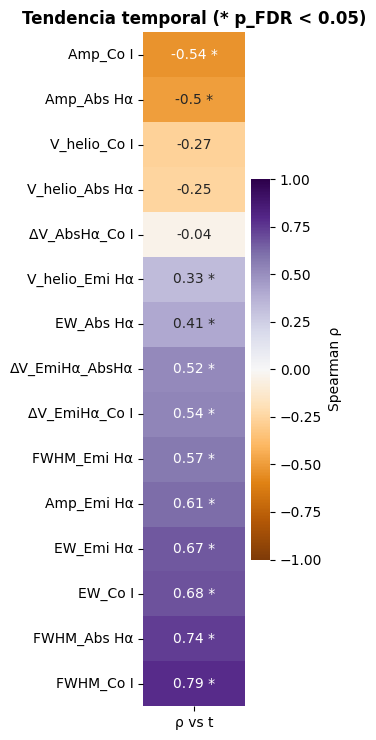

In [6]:
res_t = []

for c in cols:
    sub = ancho[['t', c]].dropna()
    if len(sub) >= 5:
        r, p = spearmanr(sub['t'], sub[c])
        res_t.append((c, len(sub), r, p))

res_t = pd.DataFrame(res_t, columns=['variable', 'n', 'ρ vs t', 'p'])
res_t['p_FDR'] = multipletests(res_t['p'], method='fdr_bh')[1]
print(res_t.sort_values('p'))

# Orden por ρ y marca de significancia según p_FDR
tab = res_t.set_index('variable').sort_values('ρ vs t')
etiquetas = tab['ρ vs t'].round(2).astype(str) + np.where(tab['p_FDR'] < 0.05, ' *', '')

plt.figure(figsize=(3.5, 0.4 * len(tab) + 1.5))
sns.heatmap(tab[['ρ vs t']], annot=etiquetas.to_frame(), fmt='', cmap='PuOr', vmin=-1, vmax=1, cbar_kws={'label': 'Spearman ρ'})
plt.title('Tendencia temporal (* p_FDR < 0.05)', fontsize=12, fontweight="bold")
plt.ylabel('')
plt.tight_layout()
plt.savefig('./Graficas analisis Antares/Spearman/Spearman tendencia temporal.png', dpi=150, bbox_inches='tight')
plt.show()

<h4 style="color: #e19edc;"> Análisis estadístico de Kruskal-Wallis</h4>

In [7]:
colores = {"Emisión Azul Hα": "turquoise", "Absorción Hα": "deepskyblue", "Absorción Cobalto": "purple"}
marcadores = {"Emisión Azul Hα": "o", "Absorción Hα": "s", "Absorción Cobalto": "^"}

<h5 style="color: #e19edc;"> Evolución temporal de cada parámetro</h5>

orden = ['Abs Hα', 'Emi Hα', 'Co I']
 parametro   Comp  n_años  n       H  p_FDR   eps2               efecto
Centro [Å] Abs Hα       4 42 10.3053 0.0169 0.2513 relativamente fuerte
Centro [Å] Emi Hα       4 42 31.1690 0.0000 0.7602           muy fuerte
Centro [Å]   Co I       4 42 11.8091 0.0091 0.2880 relativamente fuerte
         z Abs Hα       4 42 10.2028 0.0169 0.2488 relativamente fuerte
         z Emi Hα       4 42 31.1149 0.0000 0.7589           muy fuerte
         z   Co I       4 42 12.0064 0.0088 0.2928 relativamente fuerte
   V_helio Abs Hα       4 42 27.2140 0.0000 0.6638           muy fuerte
   V_helio Emi Hα       4 42 36.5864 0.0000 0.8924           muy fuerte
   V_helio   Co I       4 42 34.4861 0.0000 0.8411           muy fuerte
       Amp Abs Hα       4 42 22.8108 0.0001 0.5564               fuerte
       Amp Emi Hα       4 42 23.2791 0.0001 0.5678               fuerte
       Amp   Co I       4 42 22.3472 0.0001 0.5451               fuerte
      FWHM Abs Hα       4 4

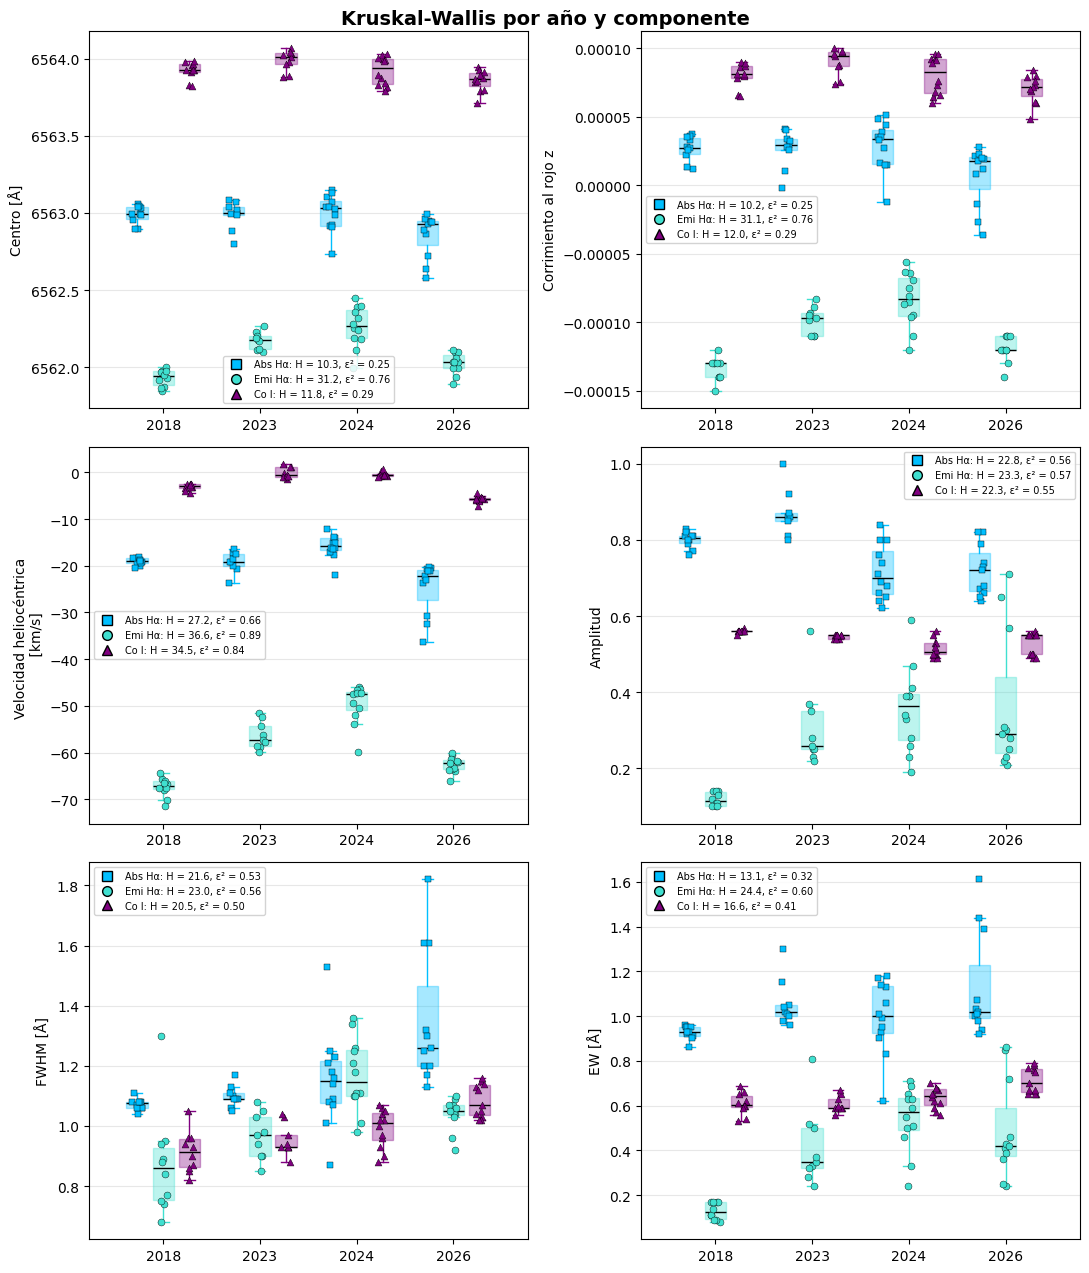

In [20]:
parametros_kw = {'Centro [Å]': 'Centro [Å]','z': 'Corrimiento al rojo z', 'V_helio': 'Velocidad heliocéntrica \n [km/s]', 'Amp': 'Amplitud', 'FWHM': 'FWHM [Å]', 'EW': 'EW [Å]'}

nombres = datos['Comp'].unique().tolist()
orden = [next(n for n in nombres if n.startswith(p)) for p in ('Abs', 'Emi', 'Co')]
print('orden =', orden)

nombre_completo = datos.drop_duplicates('Comp').set_index('Comp')['Componente'].to_dict()

col_c = {c: colores.get(nombre_completo[c], 'gray') for c in orden}
mar_c = {c: marcadores.get(nombre_completo[c], 'o') for c in orden}
desp  = dict(zip(orden, (-0.27, 0.0, 0.27)))

# Kruskal-Wallis por año y componente

filas = []

for v in parametros_kw:
    for c in orden:
        d = datos[datos['Comp'] == c].dropna(subset=[v])
        grupos = [g[v].values for _, g in d.groupby('Año') if len(g) >= 3]
        if len(grupos) >= 2:
            H, p = kruskal(*grupos)
            filas.append((v, c, len(grupos), H, p))

res_kw2 = pd.DataFrame(filas, columns=['parametro', 'Comp', 'n_años', 'H', 'p'])
res_kw2['p_FDR'] = multipletests(res_kw2['p'], method='fdr_bh')[1]

def datos_validos(comp, par):
    d = datos[datos['Comp'] == comp].dropna(subset=[par])
    return d.groupby('Año').filter(lambda g: len(g) >= 3)

res_kw2['n'] = [len(datos_validos(r.Comp, r.parametro)) for r in res_kw2.itertuples()]

# Fórmula de ε² = H / ( n - 1 ), donde n es el número total de observaciones válidas

res_kw2['eps2'] = res_kw2['H'] / (res_kw2['n'] - 1) 

def magnitud(e):
    return 'muy fuerte' if e > 0.64 else 'fuerte' if e > 0.36 and e < 0.64 else 'relativamente fuerte' if e > 0.16 and e < 0.36 else "despreciable"
res_kw2['efecto'] = res_kw2['eps2'].apply(magnitud)

print(res_kw2[['parametro', 'Comp', 'n_años', 'n', 'H', 'p_FDR', 'eps2', 'efecto']].round(4).to_string(index=False))

# Figura de Bigotes

anios = sorted(a for a, g in datos.groupby('Año')
               if (g.groupby('Comp').size() >= 3).any())
x0 = {a: i for i, a in enumerate(anios)}
rng = np.random.default_rng(0)

n_par = len(parametros_kw)
nrows = 3 if n_par > 4 else 2
ncols =  math.ceil(n_par / nrows)


fig, axs = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows))
axs = np.atleast_1d(axs).ravel()

for ax, (v, etiqueta) in zip(axs, parametros_kw.items()):
    handles = []
    for c in orden:
        d = datos[(datos['Comp'] == c) & (datos['Año'].isin(anios))].dropna(subset=[v])
        for a, g in d.groupby('Año'):
            pos = x0[a] + desp[c]
            if len(g) >= 3:
                ax.boxplot(g[v].values, positions=[pos], widths=0.22, showfliers=False,
                           patch_artist=True,
                           boxprops=dict(facecolor=col_c[c], alpha=0.35, edgecolor=col_c[c]),
                           medianprops=dict(color='k'),
                           whiskerprops=dict(color=col_c[c]), capprops=dict(color=col_c[c]))
            ax.scatter(pos + rng.uniform(-0.05, 0.05, len(g)), g[v], color=col_c[c],
                       marker=mar_c[c], s=25, edgecolor='k', linewidth=0.3, zorder=3)

        f = res_kw2[(res_kw2['parametro'] == v) & (res_kw2['Comp'] == c)]

        if len(f):
            f = f.iloc[0]
            txt = (f"{c}: H = {f['H']:.1f}, ε² = {f['eps2']:.2f}")
        else:
            txt = f"{c}: sin prueba (n insuficiente)"
        handles.append(Line2D([], [], color=col_c[c], marker=mar_c[c], ls='',
                              markeredgecolor='k', markersize=7, label=txt))

    ax.set_xticks(range(len(anios))); ax.set_xticklabels(anios)
    ax.set_ylabel(etiqueta); ax.grid(alpha=0.3, axis='y')
    ax.legend(handles=handles, fontsize=7, loc='best', framealpha=0.85)

# Ocultar ejes sobrantes
for ax in axs[n_par:]:
    ax.set_visible(False)
    

fig.suptitle('Kruskal-Wallis por año y componente', fontsize=14, fontweight='bold', y = 0.94)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('./Graficas analisis Antares/Kruskal-Wallis/KW por año y componente.png', dpi=150, bbox_inches='tight')
plt.show()

<h5 style="color: #e19edc;"> Post-hoc de Dunn (KW significativo)</h5>

In [21]:
sig = res_kw2[res_kw2['p_FDR'] < 0.05]
dunn_res = {}

for r in sig.itertuples():
    d = datos_validos(r.Comp, r.parametro)

    dunn_res[(r.parametro, r.Comp)] = sp.posthoc_dunn(d, val_col=r.parametro, group_col='Año', p_adjust='fdr_bh')

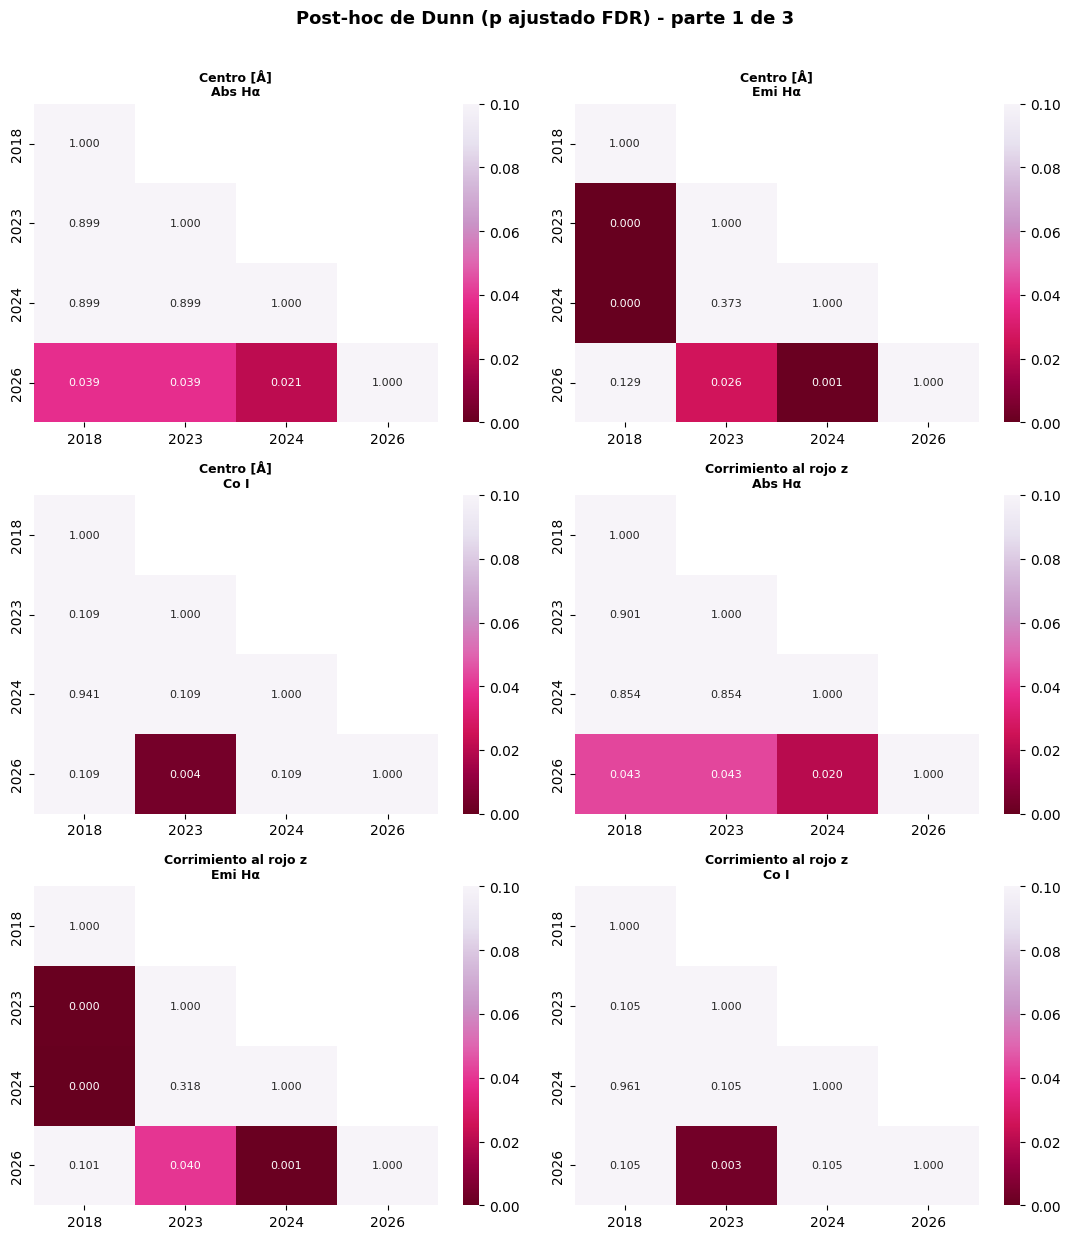

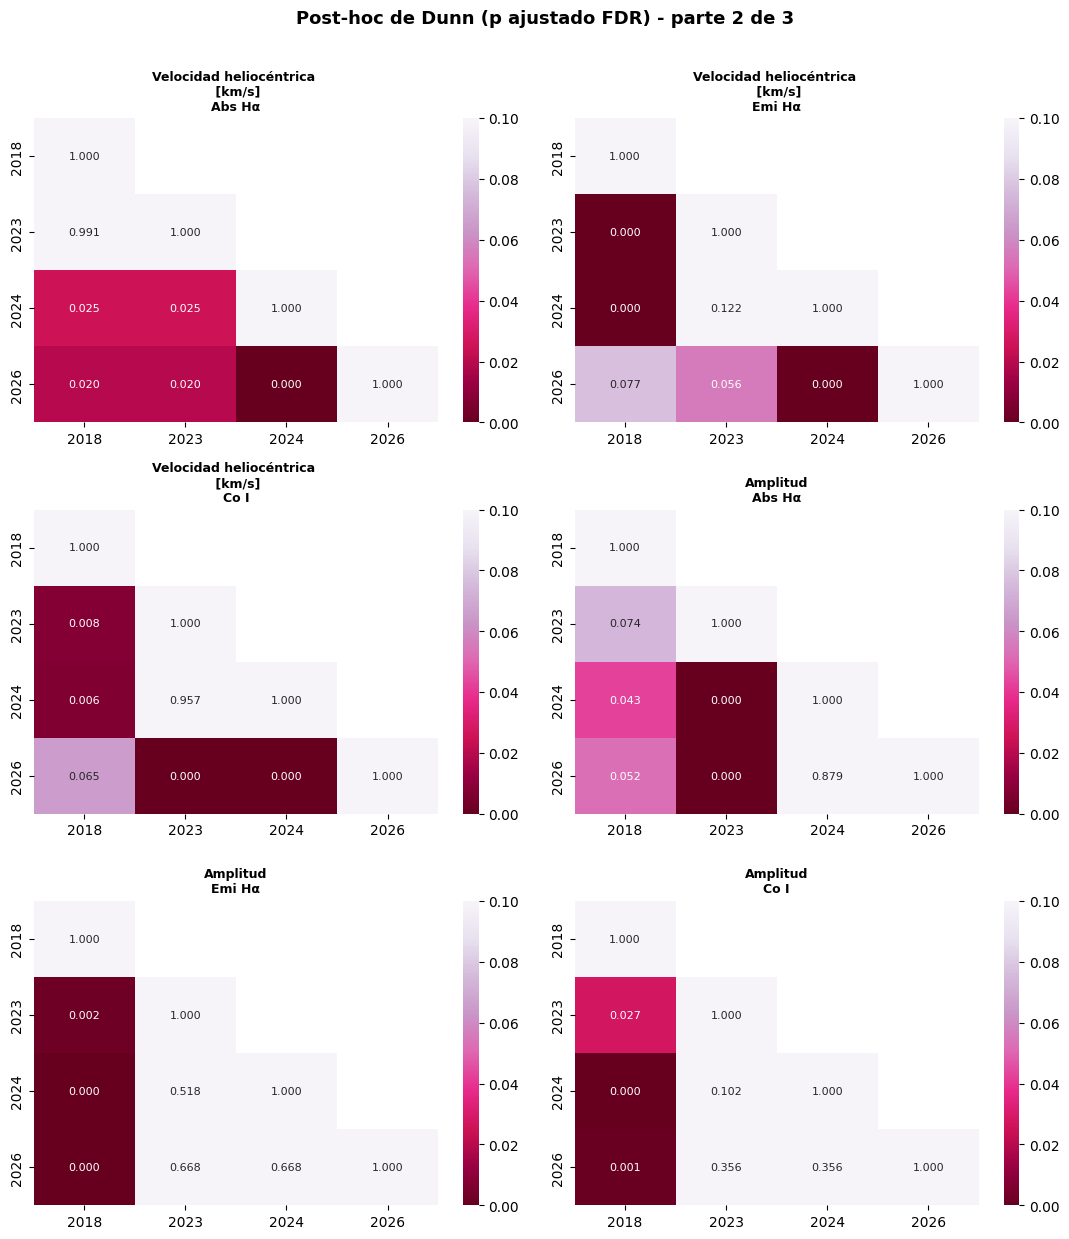

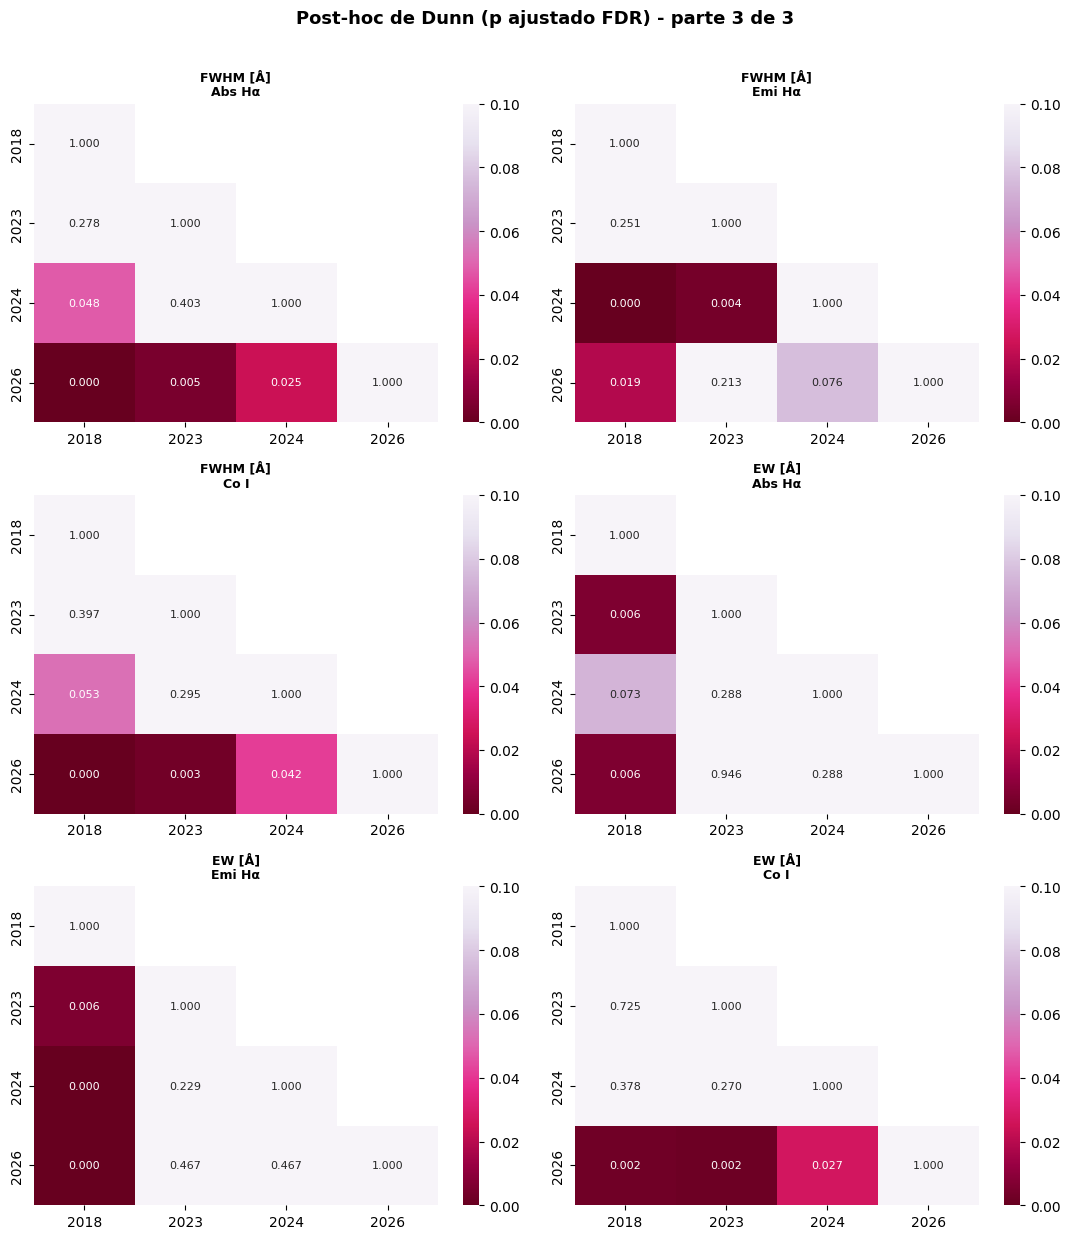

In [25]:
items = list(dunn_res.items())
ncols = 2
nrows_max = 3
por_fig = ncols * nrows_max            # 6 mapas por imagen
n_figs = math.ceil(len(items) / por_fig)

for k in range(n_figs):
    bloque = items[k * por_fig:(k + 1) * por_fig]
    nrows = math.ceil(len(bloque) / ncols)

    fig, axs = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.2 * nrows))
    axs = np.atleast_1d(axs).ravel()

    for ax, ((par, comp), mat) in zip(axs, bloque):

        mask = np.triu(np.ones_like(mat, dtype=bool), k = 1)   # Muestra el triángulo inferior de la matriz

        sns.heatmap(mat.astype(float), mask=mask, annot=True, fmt='.3f', cmap='PuRd_r',
            vmin=0, vmax=0.1, cbar=True, ax=ax, annot_kws={'fontsize': 8})

        ax.set_title(f'{parametros_kw[par]}\n{comp}', fontsize=9, fontweight='bold')
        ax.set_xlabel(''); ax.set_ylabel('')

    for ax in axs[len(bloque):]:
        ax.set_visible(False)

    fig.suptitle(f'Post-hoc de Dunn (p ajustado FDR) - parte {k + 1} de {n_figs}',
                 fontsize=13, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f'./Graficas analisis Antares/Kruskal-Wallis/Dunn posthoc parte {k + 1}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

<h5 style="color: #e19edc;"> Tabla de KW con p y medianas</h5>

In [26]:
filas_p, filas_t = [], []

for (par, comp), mat in dunn_res.items():
    d = datos_validos(comp, par)
    med = d.groupby('Año')[par].median()

    base = {'Parámetro': parametros_kw[par], 'Componente': comp}
    fp, ft = dict(base), dict(base)
    n_sig = 0

    for a, b in combinations(mat.index.tolist(), 2):
        p = mat.loc[a, b]
        dm = med[b] - med[a]
        fp[f'{a} vs {b}'] = p
        ft[f'{a} vs {b}'] = f'{p:.3f} | Δ={dm:+.3g}'
        n_sig += p < 0.05

    fp['Nº pares sig.'] = ft['Nº pares sig.'] = n_sig
    filas_p.append(fp); filas_t.append(ft)

idx = ['Parámetro', 'Componente']
tabla_p = pd.DataFrame(filas_p).set_index(idx)
tabla_t = pd.DataFrame(filas_t).set_index(idx)
cols_p = [c for c in tabla_p.columns if ' vs ' in c]

# eps2 y efecto
if 'eps2' in res_kw2.columns:
    eps = res_kw2.assign(Parámetro=res_kw2['parametro'].map(parametros_kw)) \
                 .set_index(['Parámetro', 'Comp'])[['eps2', 'efecto']]
    eps.index.names = idx
    tabla_t = tabla_t.join(eps)

def resaltar(v):
    if pd.isna(v):
        return ''
    if v < 0.001: return 'background-color:#67001f; color:white'      # ***
    if v < 0.01:  return 'background-color:#ce1256; color:white'      # **
    if v < 0.05:  return 'background-color:#df65b0; color:black'    # *
    return  'background-color:#f1eef6; color:#777777'              # no significativo

def colores_desde_p(_):
    return tabla_p[cols_p].map(resaltar).reindex(
        index=tabla_t.index, columns=tabla_t.columns, fill_value='')

estilo_t = (tabla_t.style
          .apply(colores_desde_p, axis=None)
          .format({'eps2': '{:.2f}'}, na_rep='-')
          .set_caption('Post-hoc de Dunn: p ajustado (FDR) | Δ = mediana (2do año) − mediana(1er año)'))
display(estilo_t)

In [27]:
estilo_t.to_excel('./Graficas analisis Antares/Kruskal-Wallis/Resumen_Dunn.xlsx', engine='openpyxl')

<h3 style="color: #e19edc;"> Periodogramas</h3>
<h4 style="color: #e19edc;"> Velocidades y desfases</h4>
<h5 style="color: #e19edc;"> Gráficas individuales</h5>

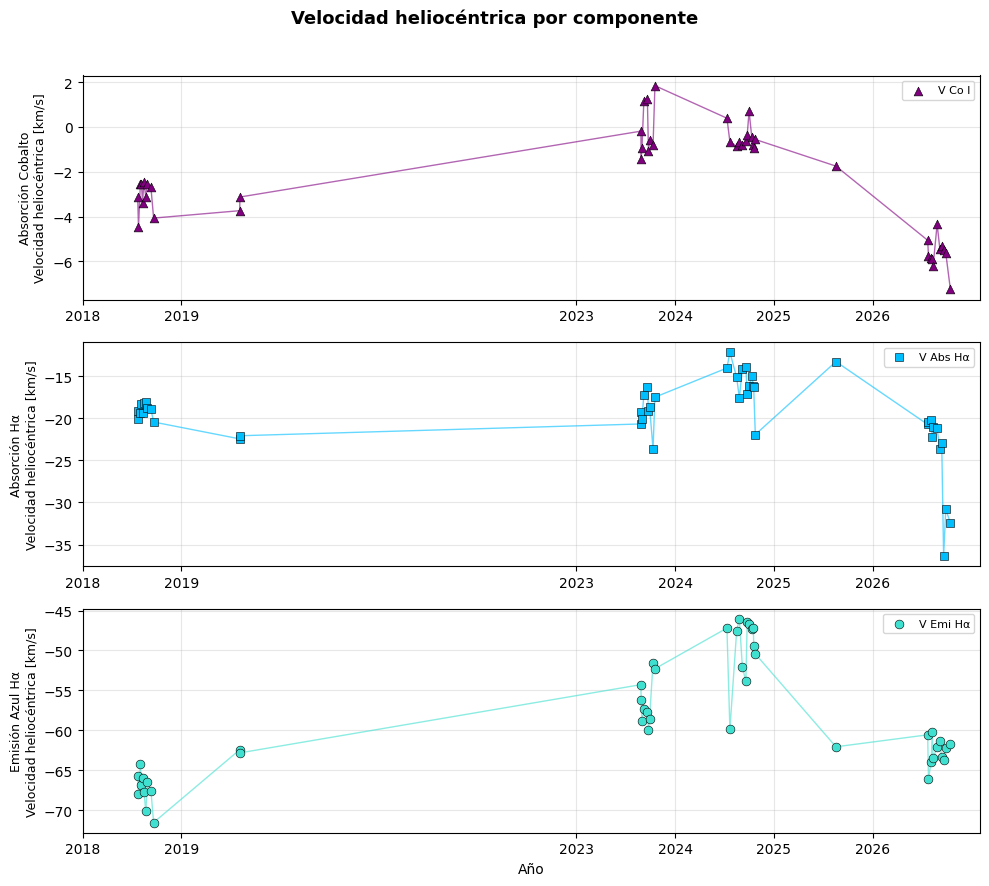

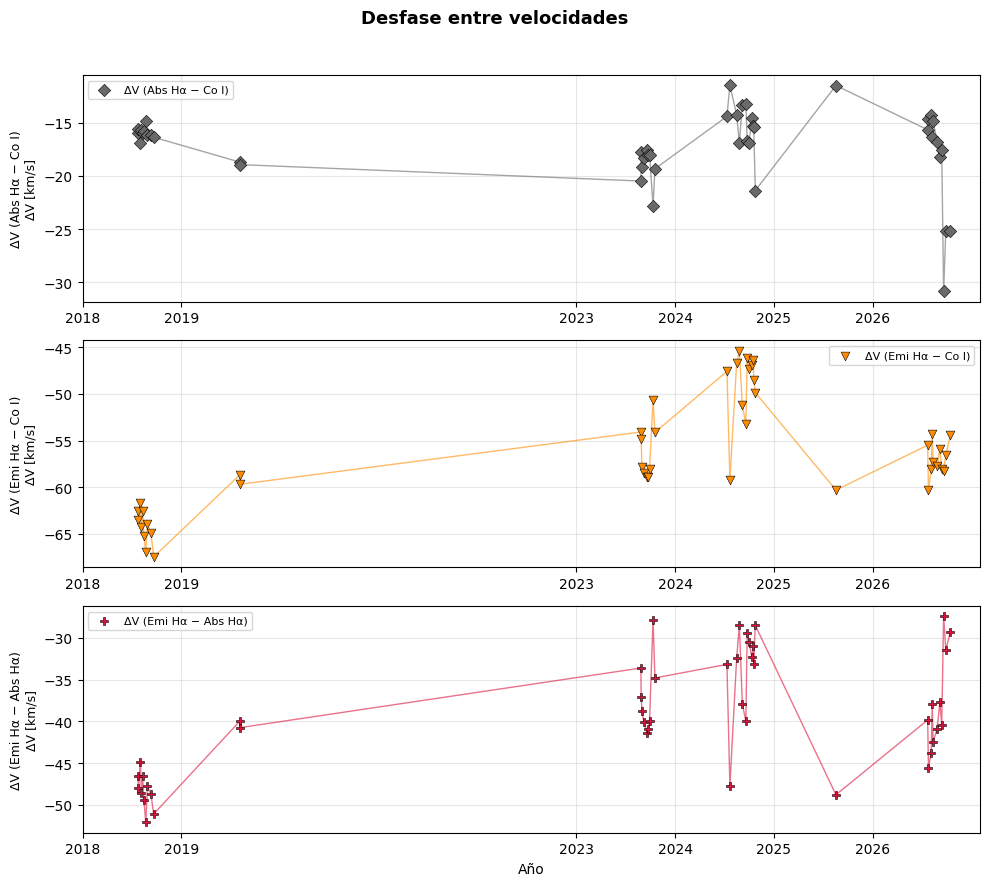

In [14]:
series = [V_co, V_abs, V_emi] + list(difs)

T_MIN, T_MAX = -np.inf, np.inf

estilo_v = {
    V_co:  ('Absorción Cobalto', 'V Co I'),
    V_abs: ('Absorción Hα',      'V Abs Hα'),
    V_emi: ('Emisión Azul Hα',   'V Emi Hα'),
}

estilo_dif = {
    'ΔV_AbsHα_Co I':  ('dimgray', 'D', 'ΔV (Abs Hα − Co I)'),
    'ΔV_EmiHα_Co I':  ('darkorange', 'v', 'ΔV (Emi Hα − Co I)'),
    'ΔV_EmiHα_AbsHα': ('crimson', 'P', 'ΔV (Emi Hα − Abs Hα)'),
}

def col_mar_lab(c):
    if c in estilo_v:
        comp, lab = estilo_v[c]
        return colores[comp], marcadores[comp], lab
    return estilo_dif[c]

A = ancho.copy()    

xlim = (A['t'].min() - 0.3, A['t'].max() + 0.3)
anios_ticks = sorted(A['Año'].unique())

def panel(ax, c, color, marcador, lab, ylabel, comp, cero=False):
    sub = A[['t', c]].dropna()

    ax.plot(sub['t'], sub[c], '-', color=color, lw=1, alpha=0.6)
    ax.scatter(sub['t'], sub[c], color=color, marker=marcador, s=40,
               edgecolor='k', linewidth=0.4, zorder=3,
               label=f'{lab}')

    if cero:
        ax.axhline(0, color='k', lw=0.6, ls='--')

    ax.set_ylabel(f'{comp}\n{ylabel}', fontsize=9)

    ax.set_xlim(xlim)
    ax.set_xticks(anios_ticks)
    ax.set_xticklabels(anios_ticks)
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='best')

# Periodigrama de las velocidades heliocéntricas

fig1, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for ax, (c, (comp, lab)) in zip(axs, estilo_v.items()):
    panel(ax, c, colores[comp], marcadores[comp], lab,
      'Velocidad heliocéntrica [km/s]', comp)

axs[-1].set_xlabel('Año')

fig1.suptitle('Velocidad heliocéntrica por componente', fontsize=13, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('./Graficas analisis Antares/Periodogramas/Individuales/Velocidades helio.png', dpi=150, bbox_inches='tight')
plt.show()

# Periodigrama de los desfases entre velocidades

fig2, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for ax, (c, (color, marcador, lab)) in zip(axs, estilo_dif.items()):
    panel(ax, c, color, marcador, lab, 'ΔV [km/s]', lab)

axs[-1].set_xlabel('Año')

fig2.suptitle('Desfase entre velocidades', fontsize=13, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('./Graficas analisis Antares/Periodogramas/Individuales/Desfases velocidades.png',
            dpi=150, bbox_inches='tight')
plt.show()

<h5 style="color: #e19edc;"> Gráficas conjuntas</h5>

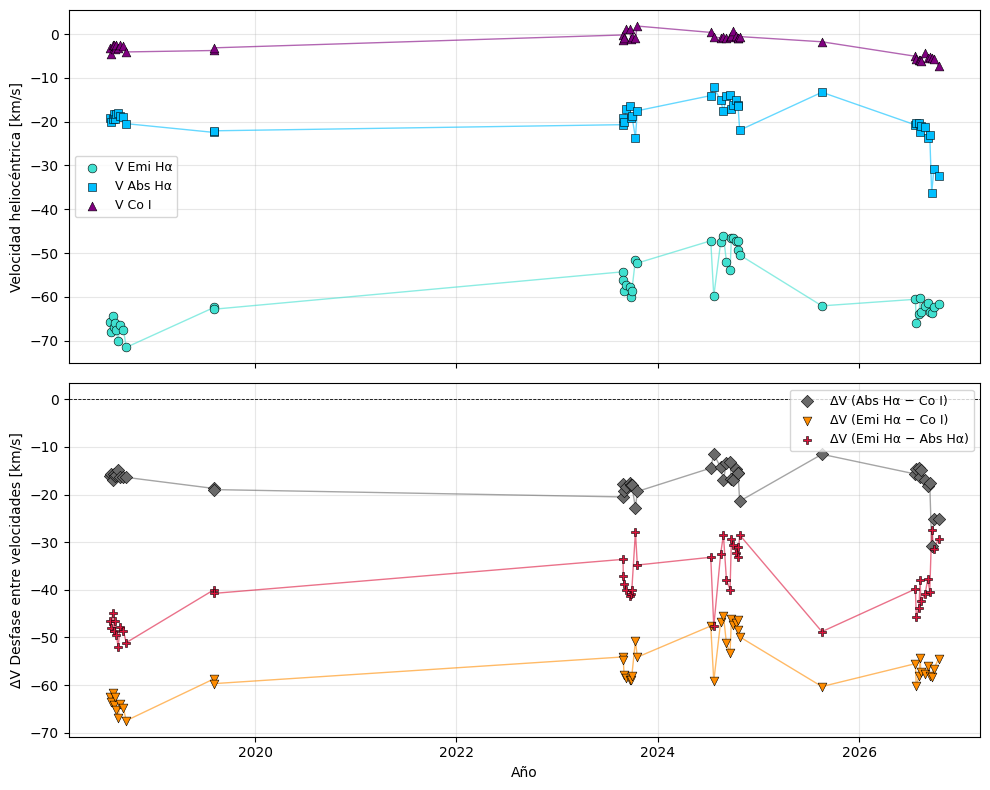

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Periodigrama de las velocidades heliocéntricas en conjunto

for c in [V_emi, V_abs, V_co]:

    comp, lab = estilo_v[c]
    sub = A[['t', c]].dropna()
    ax1.plot(sub['t'], sub[c], '-', color=colores[comp], lw=1, alpha=0.6)
    ax1.scatter(sub['t'], sub[c], color=colores[comp], marker=marcadores[comp],
                s=40, edgecolor='k', linewidth=0.4, zorder=3, label=lab)
ax1.set_ylabel('Velocidad heliocéntrica [km/s]')
ax1.grid(alpha=0.3); ax1.legend(fontsize=9)

# Periodigrama de los desfases entre velocidades en conjunto

for c, (color, marcador, lab) in estilo_dif.items():
    sub = A[['t', c]].dropna()
    ax2.plot(sub['t'], sub[c], '-', color=color, lw=1, alpha=0.6)
    ax2.scatter(sub['t'], sub[c], color=color, marker=marcador,
                s=40, edgecolor='k', linewidth=0.4, zorder=3, label=lab)
ax2.axhline(0, color='k', lw=0.6, ls='--')
ax2.set_ylabel('ΔV Desfase entre velocidades [km/s]')
ax2.set_xlabel('Año')
ax2.grid(alpha=0.3); ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('./Graficas analisis Antares/Periodogramas/Conjuntas/Velocidades y desfases conjuntas.png', dpi=150, bbox_inches='tight')
plt.show()

<h5 style="color: #e19edc;"> Periodograma en la zona del ciclo largo</h5>

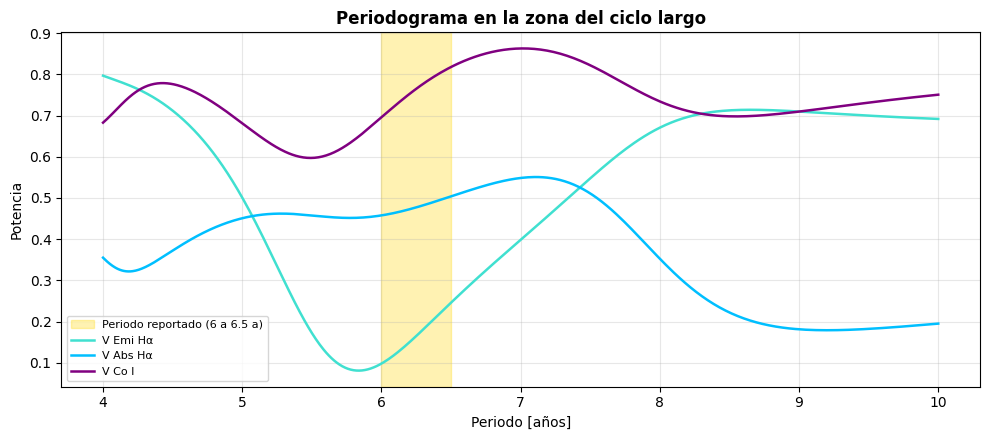

V_helio_Emi Hα: potencia a P=6.25 a = 0.17
V_helio_Abs Hα: potencia a P=6.25 a = 0.48
V_helio_Co I: potencia a P=6.25 a = 0.76


In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(6.0, 6.5, color='gold', alpha=0.3, label='Periodo reportado (6 a 6.5 a)')

for c in [V_emi, V_abs, V_co]:
    comp, lab = estilo_v[c]
    sub = A[['t', c]].dropna()
    ls = LombScargle(sub['t'], sub[c])
    freq = np.linspace(1/10, 1/4, 500)
    power = ls.power(freq)
    ax.plot(1/freq, power, color=colores[comp], lw=1.8, label=lab)

ax.set_xlabel('Periodo [años]'); ax.set_ylabel('Potencia')
ax.set_title('Periodograma en la zona del ciclo largo', fontweight='bold')
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('./Graficas analisis Antares/Periodogramas/Conjuntas/Periodograma ciclo largo.png', dpi=150, bbox_inches='tight')
plt.show()

# Ajuste con periodo fijo de 6.25 años
for c in [V_emi, V_abs, V_co]:
    sub = A[['t', c]].dropna()
    ls = LombScargle(sub['t'], sub[c])
    print(f'{c}: potencia a P=6.25 a = {ls.power(1/6.25):.2f}')